## Método de biseccion 

In [1]:
def biseccion(f, a, b, TOL=1e-6, N0=100):
    """Devuelve (p, historia), con historia = [(a, b, p) por iteración]."""
    FA = f(a)
    historia = []
    i = 1
    while i <= N0:
        p = a + (b-a)/2                             # COMPLETE: punto medio estable
        FP = f(p)
        historia.append((a, b, p))                        # COMPLETE: (a, b, p)
        if FP == 0 or (b-a)/2 < TOL:                          # COMPLETE: parada por TOL
            return p, historia
        i = i + 1
        if FA * FP > 0:
            a = p                                     # COMPLETE: mover a y FA
            FA = FP
        else:
            b = p                                     # COMPLETE: mover b
    raise RuntimeError(f"fracasó después de {N0} iteraciones")


def f(x):
    return x**3 + 4*x**2 - 10



biseccion(f, 1, 2 , 1e-2)

(1.3671875,
 [(1, 2, 1.5),
  (1, 1.5, 1.25),
  (1.25, 1.5, 1.375),
  (1.25, 1.375, 1.3125),
  (1.3125, 1.375, 1.34375),
  (1.34375, 1.375, 1.359375),
  (1.359375, 1.375, 1.3671875)])

## Segundo ejercicio 

In [2]:
import numpy as np
import matplotlib.pyplot as plt

g = 9.81
s0, m, k = 300.0, 0.25, 0.1


def s(t):
    return s0 - (m * g / k) * t + (m ** 2 * g / k ** 2) * (1 - np.exp(-k * t / m))

In [3]:
biseccion(s, 0, 20, 1e-4)

(14.725570678710938,
 [(0, 20, 10.0),
  (10.0, 20, 15.0),
  (10.0, 15.0, 12.5),
  (12.5, 15.0, 13.75),
  (13.75, 15.0, 14.375),
  (14.375, 15.0, 14.6875),
  (14.6875, 15.0, 14.84375),
  (14.6875, 14.84375, 14.765625),
  (14.6875, 14.765625, 14.7265625),
  (14.6875, 14.7265625, 14.70703125),
  (14.70703125, 14.7265625, 14.716796875),
  (14.716796875, 14.7265625, 14.7216796875),
  (14.7216796875, 14.7265625, 14.72412109375),
  (14.72412109375, 14.7265625, 14.725341796875),
  (14.725341796875, 14.7265625, 14.7259521484375),
  (14.725341796875, 14.7259521484375, 14.72564697265625),
  (14.725341796875, 14.72564697265625, 14.725494384765625),
  (14.725494384765625, 14.72564697265625, 14.725570678710938)])

### Gráfica

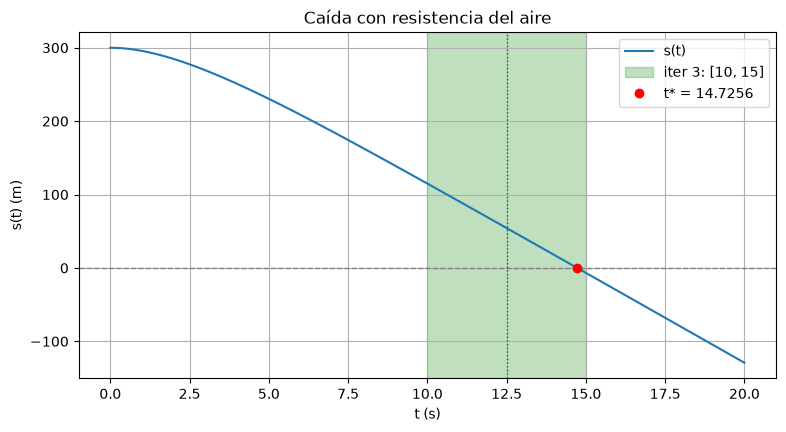

In [4]:
def graficar(t_star, historia, k_iteracion=None, archivo="caida.png"):
    """Dibuja s(t). Si k_iteracion no es None, resalta el intervalo [a, b]
    de esa iteración (1-based) y su punto medio p."""
    t = np.linspace(0, 20, 400)
    plt.figure(figsize=(9, 4.5))
    plt.plot(t, s(t), label="s(t)")
    plt.axhline(0, color="gray", linestyle="--", linewidth=1)
    if k_iteracion is not None:
        a, b, p = historia[k_iteracion - 1]
        plt.axvspan(a, b, color="green", alpha=0.25,
                    label=f"iter {k_iteracion}: [{a:.4g}, {b:.4g}]")
        plt.axvline(p, color="green", linestyle=":", linewidth=1)
    plt.plot(t_star, 0, "ro", label=f"t* = {t_star:.4f}")
    plt.xlabel("t (s)")
    plt.ylabel("s(t) (m)")
    plt.title("Caída con resistencia del aire")
    plt.legend()
    plt.grid(True)
    plt.savefig(archivo, dpi=150)
    plt.show()

t_star, historia = biseccion(s, 0.0, 20.0, TOL=1e-4)
graficar(t_star, historia, k_iteracion=3)